# 08 - Respuestas a las preguntas de negocio

Aquí se responden las ocho preguntas planteadas en la primera entrega (numeral 2 de la entrega final). Todo sale de la capa oro que deja el notebook 07; las agregaciones grandes se hacen en Spark y a pandas solo pasan tablas pequeñas.

Tres cosas para leer bien los resultados:

- **Las tasas son anuales y por cada 100.000 habitantes**, promediando los años completos 2019 a 2025. Se usan tasas y no conteos porque un barrio con más gente tiene más arrestos y más choques solo por tener más gente.
- **Los arrestos miden la actividad de la policía, no la criminalidad.** Una tasa alta puede reflejar más delitos o más presencia policial.
- **La población es la de residentes.** En zonas a donde llega mucha gente a trabajar o de visita (sobre todo Manhattan), las tasas por residente salen infladas.

Cada pregunta termina con una frase de respuesta que se arma con los datos, para que quede escrita con las cifras de esta ejecución.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pyspark.sql import functions as F

import geo
from codigos import BANDERAS_VEHICULO, ORDEN_DIAS, SIN_CAUSA
from config import GOLD, sesion
from estilo import BOROUGHS, CATEGORICA, COLOR_BOROUGH, SECUENCIAL, TINTA, TINTA_SECUNDARIA, guardar, miles

spark = sesion("08_respuestas")
ANIOS_COMPLETOS = list(range(2019, 2026))
AZULES = LinearSegmentedColormap.from_list("azules", SECUENCIAL)
SIGLA = {"Bronx": "BX", "Brooklyn": "BK", "Manhattan": "MN", "Queens": "QN", "Staten Island": "SI"}

barrios = spark.read.parquet(f"{GOLD}/barrios").toPandas()
boroughs = spark.read.parquet(f"{GOLD}/boroughs").toPandas().set_index("borough").reindex(BOROUGHS)
arrestos_borough_anio = spark.read.parquet(f"{GOLD}/arrestos_borough_anio").toPandas()
arrestos_puma_anio = spark.read.parquet(f"{GOLD}/arrestos_puma_anio").toPandas()
delitos = spark.read.parquet(f"{GOLD}/arrestos_delito_borough").toPandas()
choques = spark.read.parquet(f"{GOLD}/choques_modelo").cache()
pumas = geo.cargar_pumas(spark)

barrios["etiqueta"] = barrios["barrio"] + " (" + barrios["borough"].map(SIGLA) + ")"
print(f"{len(barrios)} barrios | {len(boroughs)} boroughs | {choques.count():,} choques")

def fmt_miles(ax, eje="y"):
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(FuncFormatter(miles))

def barras_barrios(tabla, columna, titulo, nombre, unidad):
    """Barras horizontales de un grupo de barrios, con el color de su borough."""
    t = tabla.sort_values(columna)
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.2))
    ax.barh(t["etiqueta"], t[columna], color=[COLOR_BOROUGH[b] for b in t["borough"]], height=0.65)
    for y, v in zip(t["etiqueta"], t[columna]):
        ax.text(v, y, " " + miles(v), va="center", fontsize=8, color=TINTA_SECUNDARIA)
    fmt_miles(ax, "x"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel(unidad)
    presentes = [b for b in BOROUGHS if b in set(t["borough"])]
    ax.legend(handles=[Patch(color=COLOR_BOROUGH[b], label=b) for b in presentes], loc="lower right", fontsize=8)
    ax.set_title(titulo, pad=10)
    guardar(fig, nombre); plt.show()

def mapa_barrios(columna, titulo, nombre, unidad):
    """Mapa de los 55 barrios coloreados según una columna de la tabla de barrios."""
    valores = barrios.set_index("puma")[columna]
    norma = Normalize(valores.min(), valores.max())
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    geo.dibujar_pumas(ax, pumas, {p: AZULES(norma(v)) for p, v in valores.items()})
    barra = fig.colorbar(ScalarMappable(norm=norma, cmap=AZULES), ax=ax, shrink=0.55, pad=0.01)
    barra.set_label(unidad, fontsize=8); barra.ax.tick_params(labelsize=7)
    barra.ax.yaxis.set_major_formatter(FuncFormatter(miles))
    ax.set_title(titulo, pad=8)
    guardar(fig, nombre); plt.show()

def correlaciones(tabla, x, y):
    """Pearson (relación lineal) y Spearman (si el orden coincide) entre dos columnas.
    Spearman es la correlación de Pearson calculada sobre las posiciones (rangos)."""
    return tabla[x].corr(tabla[y]), tabla[x].rank().corr(tabla[y].rank())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/11 17:26:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/11 17:27:07 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


55 barrios | 5 boroughs | 846,420 choques


## Pregunta 1. ¿Cuál es la tasa de arrestos por cada 100.000 habitantes en cada distrito y en cada barrio, y cómo ha cambiado entre 2019 y 2026?

### Por distrito

2026 solo tiene el primer semestre. Para poder ponerlo en la misma gráfica se **anualiza** multiplicando por dos, y se dibuja con línea punteada porque es una proyección: supone que el segundo semestre será igual al primero.

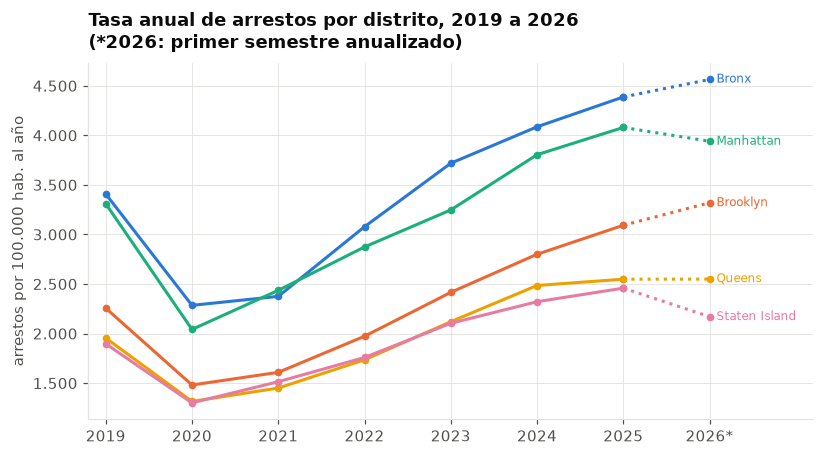

anio,2019,2020,2021,2022,2023,2024,2025,2026,promedio 2019-2025,cambio 2019-2025 %
borough,,,,,,,,,,
Bronx,3409,2285,2375,3078,3719,4086,4387,4564,3334,28.7
Brooklyn,2257,1481,1609,1973,2416,2800,3093,3320,2233,37.0
Manhattan,3310,2042,2436,2874,3247,3805,4080,3940,3113,23.2
Queens,1956,1316,1450,1735,2120,2485,2549,2550,1944,30.3
Staten Island,1897,1301,1514,1759,2104,2322,2459,2171,1908,29.6


In [2]:
ab = arrestos_borough_anio.copy()
ab["tasa"] = ab["arrestos"] / ab["borough"].map(boroughs["poblacion_2018"]) * 1e5
ab.loc[ab["anio"] == 2026, "tasa"] *= 2
tasa_anual = ab.pivot(index="anio", columns="borough", values="tasa").reindex(columns=BOROUGHS).sort_index()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for b in BOROUGHS:
    serie = tasa_anual[b]
    ax.plot(serie.loc[:2025].index, serie.loc[:2025].values, color=COLOR_BOROUGH[b], marker="o", markersize=4, label=b)
    ax.plot(serie.loc[2025:].index, serie.loc[2025:].values, color=COLOR_BOROUGH[b], linestyle=":", marker="o", markersize=4)
    ax.text(2026.08, serie.loc[2026], b, color=COLOR_BOROUGH[b], fontsize=8, va="center")
fmt_miles(ax); ax.set_xlim(2018.8, 2027.2); ax.set_xticks(range(2019, 2027))
ax.set_xticklabels([str(a) for a in range(2019, 2026)] + ["2026*"])
ax.set_ylabel("arrestos por 100.000 hab. al año")
ax.set_title("Tasa anual de arrestos por distrito, 2019 a 2026\n(*2026: primer semestre anualizado)", pad=10)
guardar(fig, "08_01_tasa_arrestos_distrito_anio"); plt.show()

tabla_1 = tasa_anual.round(0).astype(int).T
tabla_1["promedio 2019-2025"] = boroughs["tasa_arrestos"].round(0).astype(int)
tabla_1["cambio 2019-2025 %"] = (100 * (tasa_anual.loc[2025] / tasa_anual.loc[2019] - 1)).round(1)
tabla_1.to_csv("../figuras/tabla_08_p1_tasa_arrestos_distrito.csv")
tabla_1

In [3]:
orden = boroughs["tasa_arrestos"].sort_values(ascending=False)
minimo = tasa_anual.sum(axis=1).loc[:2025].idxmin()
print(f"Respuesta (distritos): la tasa promedio va de {miles(orden.iloc[0])} arrestos por 100.000 habitantes en {orden.index[0]} "
      f"a {miles(orden.iloc[-1])} en {orden.index[-1]}, {orden.iloc[0] / orden.iloc[-1]:.1f} veces más.")
print(f"El año más bajo del periodo fue {minimo}. Entre 2019 y 2025 la tasa cambió así: "
      + ", ".join(f"{b} {tabla_1.loc[b, 'cambio 2019-2025 %']:+.1f} %" for b in BOROUGHS) + ".")

Respuesta (distritos): la tasa promedio va de 3.334 arrestos por 100.000 habitantes en Bronx a 1.908 en Staten Island, 1.7 veces más.
El año más bajo del periodo fue 2020. Entre 2019 y 2025 la tasa cambió así: Bronx +28.7 %, Brooklyn +37.0 %, Manhattan +23.2 %, Queens +30.3 %, Staten Island +29.6 %.


### Por barrio

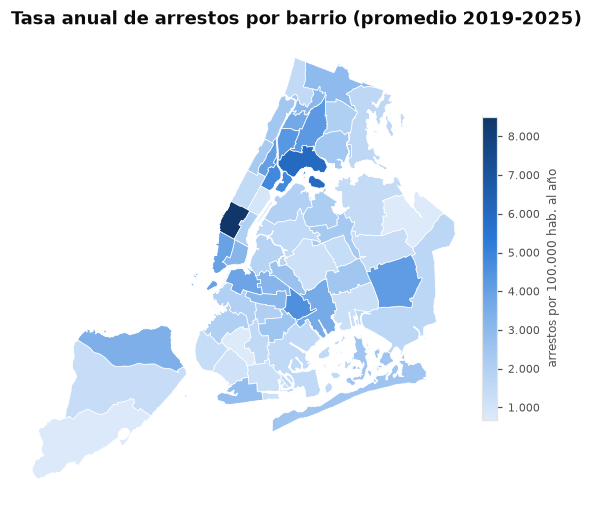

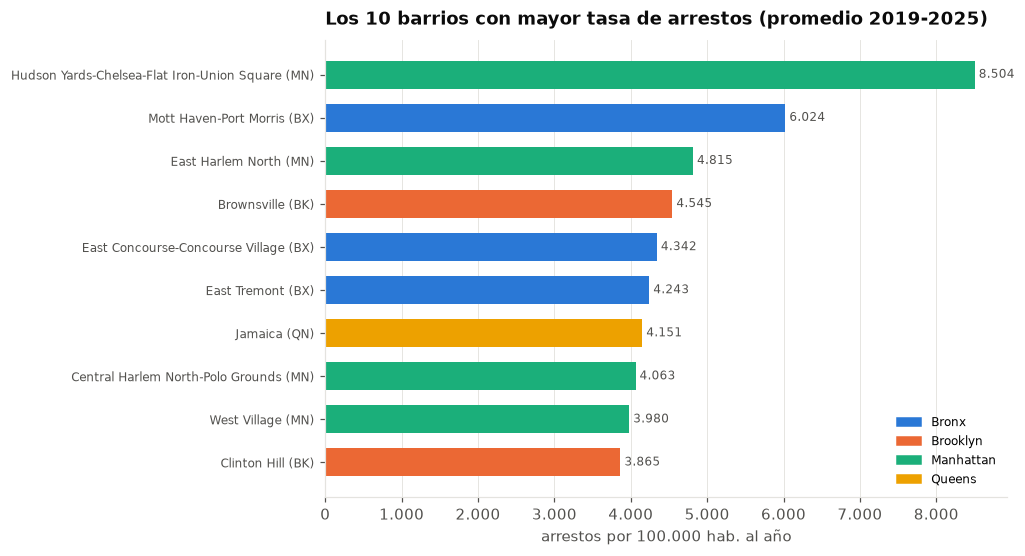

In [4]:
mapa_barrios("tasa_arrestos", "Tasa anual de arrestos por barrio (promedio 2019-2025)", "08_02_mapa_tasa_arrestos", "arrestos por 100.000 hab. al año")
barras_barrios(barrios.nlargest(10, "tasa_arrestos"), "tasa_arrestos",
               "Los 10 barrios con mayor tasa de arrestos (promedio 2019-2025)", "08_03_top_barrios_arrestos",
               "arrestos por 100.000 hab. al año")

In [5]:
ap = arrestos_puma_anio.merge(barrios[["puma", "etiqueta", "borough", "poblacion_2018"]], on="puma")
ap["tasa"] = ap["arrestos"] / ap["poblacion_2018"] * 1e5
por_anio = ap.pivot(index="etiqueta", columns="anio", values="tasa")
cambio = pd.DataFrame({
    "tasa 2019": por_anio[2019].round(0),
    "tasa 2025": por_anio[2025].round(0),
    "cambio %": (100 * (por_anio[2025] / por_anio[2019] - 1)).round(1),
}).sort_values("cambio %", ascending=False)
cambio.to_csv("../figuras/tabla_08_p1_cambio_barrios.csv")

top = barrios.nlargest(10, "tasa_arrestos")
tabla_1b = top[["etiqueta", "poblacion_2018", "tasa_arrestos", "tasa_felonias", "pct_felonias"]].round(1).reset_index(drop=True)
tabla_1b.to_csv("../figuras/tabla_08_p1_top_barrios.csv", index=False)

print(f"Respuesta (barrios): la tasa va de {miles(barrios['tasa_arrestos'].min())} a {miles(barrios['tasa_arrestos'].max())} "
      f"arrestos por 100.000 habitantes; la mediana es {miles(barrios['tasa_arrestos'].median())}.")
print(f"De los 10 barrios con mayor tasa, {top['borough'].value_counts().to_dict()} por distrito.")
print(f"Entre 2019 y 2025 la tasa subió en {(cambio['cambio %'] > 0).sum()} de los 55 barrios y bajó en {(cambio['cambio %'] < 0).sum()}.")
print("\nLos 5 barrios donde más subió y los 5 donde más bajó:")
pd.concat([cambio.head(5), cambio.tail(5)])

Respuesta (barrios): la tasa va de 686 a 8.504 arrestos por 100.000 habitantes; la mediana es 2.173.
De los 10 barrios con mayor tasa, {'Manhattan': 4, 'Bronx': 3, 'Brooklyn': 2, 'Queens': 1} por distrito.
Entre 2019 y 2025 la tasa subió en 50 de los 55 barrios y bajó en 5.

Los 5 barrios donde más subió y los 5 donde más bajó:


,tasa 2019,tasa 2025,cambio %
etiqueta,,,
Queens Village (QN),1422.0,2865.0,101.5
Bensonhurst West (BK),952.0,1680.0,76.5
Elmhurst (QN),1932.0,3359.0,73.9
Brighton Beach (BK),2761.0,4603.0,66.7
Borough Park (BK),621.0,980.0,57.9
Lower East Side (MN),3600.0,3586.0,-0.4
Morningside Heights (MN),2554.0,2525.0,-1.1
South Ozone Park (QN),1386.0,1275.0,-8.0
Great Kills (SI),797.0,713.0,-10.6


## Pregunta 2. ¿Los distritos con mayor tasa de pobreza presentan también una mayor tasa de arrestos por habitante, y esta relación se mantiene al separar felonías de delitos menores?

Solo hay cinco distritos, así que esto es una comparación descriptiva y no una prueba estadística: con cinco puntos, cualquier coeficiente de correlación es muy inestable. Se reportan dos: Pearson (qué tan cerca están de una línea recta) y Spearman (si el orden de pobreza coincide con el orden de arrestos).

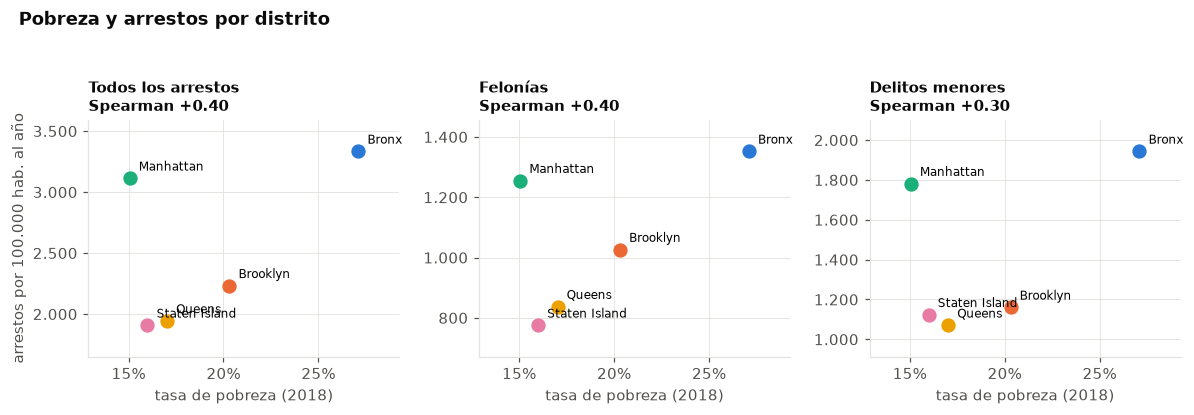

,pobreza_pct,pregrado_pct,tasa_arrestos,tasa_felonias,tasa_delitos_menores,pct_felonias
borough,,,,,,
Bronx,27.1,19.8,3334.2,1352.3,1943.5,40.6
Brooklyn,20.3,37.6,2232.7,1026.7,1160.6,46.0
Manhattan,15.1,60.9,3113.5,1255.3,1781.7,40.3
Queens,17.0,32.1,1944.4,837.4,1070.3,43.1
Staten Island,16.0,32.5,1907.8,775.4,1123.5,40.6


,pearson,spearman
serie,,
Todos los arrestos,0.52,0.4
Felonías,0.58,0.4
Delitos menores,0.50,0.3


In [6]:
series = [("tasa_arrestos", "Todos los arrestos"), ("tasa_felonias", "Felonías"), ("tasa_delitos_menores", "Delitos menores")]
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8))
filas = []
for ax, (columna, titulo) in zip(ejes, series):
    pearson, spearman = correlaciones(boroughs, "pobreza_pct", columna)
    filas.append({"serie": titulo, "pearson": round(pearson, 2), "spearman": round(spearman, 2)})
    for b in BOROUGHS:
        ax.scatter(boroughs.loc[b, "pobreza_pct"], boroughs.loc[b, columna], color=COLOR_BOROUGH[b], s=70, zorder=3)
        ax.annotate(b, (boroughs.loc[b, "pobreza_pct"], boroughs.loc[b, columna]), textcoords="offset points", xytext=(6, 5), fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0)); fmt_miles(ax)
    ax.set_xlabel("tasa de pobreza (2018)"); ax.set_title(f"{titulo}\nSpearman {spearman:+.2f}", fontsize=10)
    ax.margins(0.18)
ejes[0].set_ylabel("arrestos por 100.000 hab. al año")
fig.suptitle("Pobreza y arrestos por distrito", x=0.02, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout(rect=[0, 0, 1, 0.94])
guardar(fig, "08_04_pobreza_arrestos"); plt.show()

tabla_2 = boroughs[["pobreza_pct", "pregrado_pct", "tasa_arrestos", "tasa_felonias", "tasa_delitos_menores", "pct_felonias"]].round(1)
tabla_2.to_csv("../figuras/tabla_08_p2_pobreza_arrestos.csv")
correlacion_2 = pd.DataFrame(filas).set_index("serie")
correlacion_2.to_csv("../figuras/tabla_08_p2_correlaciones.csv")
display(tabla_2); correlacion_2

In [7]:
mas_pobre, menos_pobre = boroughs["pobreza_pct"].idxmax(), boroughs["pobreza_pct"].idxmin()
print(f"Respuesta: {mas_pobre} es el distrito más pobre ({boroughs.loc[mas_pobre, 'pobreza_pct']:.1f} %) y su tasa de arrestos es "
      f"{miles(boroughs.loc[mas_pobre, 'tasa_arrestos'])}; {menos_pobre} es el menos pobre ({boroughs.loc[menos_pobre, 'pobreza_pct']:.1f} %) "
      f"y su tasa es {miles(boroughs.loc[menos_pobre, 'tasa_arrestos'])}.")
for serie, fila in correlacion_2.iterrows():
    print(f"  {serie}: Spearman {fila['spearman']:+.2f}, Pearson {fila['pearson']:+.2f}")
print("Si Manhattan aparece con una tasa alta pese a su baja pobreza, es el efecto de la población flotante: "
      "los arrestos ocurren ahí, pero muchas de esas personas no viven ahí.")
sin_mn = boroughs.drop(index="Manhattan")
print("Spearman sin Manhattan (4 distritos):", ", ".join(f"{t} {correlaciones(sin_mn, 'pobreza_pct', c)[1]:+.2f}" for c, t in series))

Respuesta: Bronx es el distrito más pobre (27.1 %) y su tasa de arrestos es 3.334; Manhattan es el menos pobre (15.1 %) y su tasa es 3.113.
  Todos los arrestos: Spearman +0.40, Pearson +0.52
  Felonías: Spearman +0.40, Pearson +0.58
  Delitos menores: Spearman +0.30, Pearson +0.50
Si Manhattan aparece con una tasa alta pese a su baja pobreza, es el efecto de la población flotante: los arrestos ocurren ahí, pero muchas de esas personas no viven ahí.
Spearman sin Manhattan (4 distritos): Todos los arrestos +1.00, Felonías +1.00, Delitos menores +0.80


## Pregunta 3. ¿Qué tipos de delito predominan en los distritos con mayor pobreza frente a los de menor pobreza?

Se comparan los dos distritos con mayor tasa de pobreza contra los dos con menor tasa. Para cada grupo se calcula qué porcentaje de sus arrestos corresponde a cada tipo de delito, y la diferencia se mide en puntos porcentuales. Se comparan porcentajes y no conteos, para que el tamaño de cada distrito no influya.

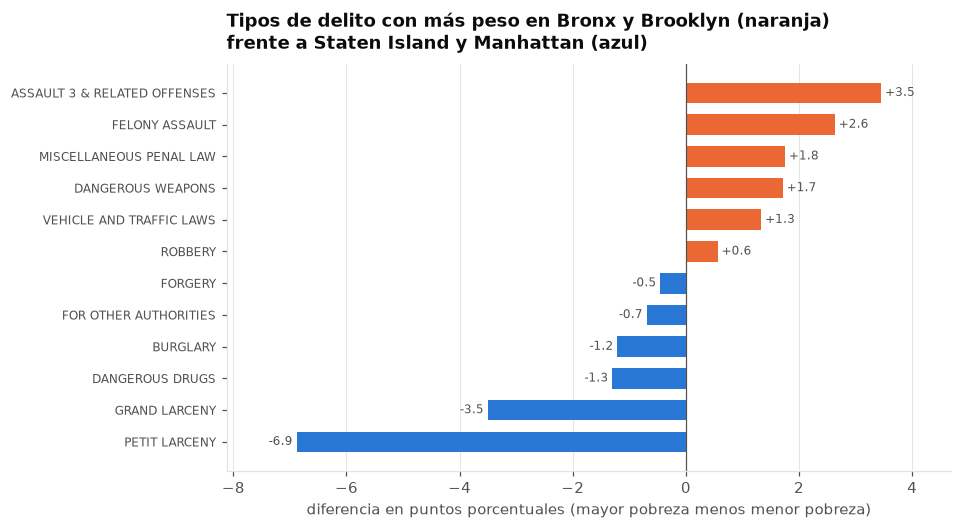

grupo,mayor pobreza,menor pobreza,diferencia_pp
ofns_desc,,,
ASSAULT 3 & RELATED OFFENSES,16.12,12.67,3.45
FELONY ASSAULT,9.59,6.96,2.63
MISCELLANEOUS PENAL LAW,6.50,4.76,1.75
DANGEROUS WEAPONS,4.83,3.12,1.71
VEHICLE AND TRAFFIC LAWS,5.46,4.14,1.33
ROBBERY,4.91,4.35,0.56
OTHER STATE LAWS,1.27,0.78,0.50
OTHER OFFENSES RELATED TO THEF,1.17,0.83,0.33
OTHER OFFENSES RELATED TO THEFT,2.63,2.35,0.28


In [8]:
orden_pobreza = boroughs["pobreza_pct"].sort_values(ascending=False)
mas_pobres, menos_pobres = list(orden_pobreza.index[:2]), list(orden_pobreza.index[-2:])
delitos["grupo"] = np.select([delitos["borough"].isin(mas_pobres), delitos["borough"].isin(menos_pobres)], ["mayor pobreza", "menor pobreza"], "intermedio")
delitos["ofns_desc"] = delitos["ofns_desc"].fillna("(sin dato)")

por_grupo = delitos[delitos["grupo"] != "intermedio"].pivot_table(index="ofns_desc", columns="grupo", values="count", aggfunc="sum", fill_value=0)
participacion = 100 * por_grupo / por_grupo.sum()
participacion["diferencia_pp"] = participacion["mayor pobreza"] - participacion["menor pobreza"]
frecuentes = participacion[(participacion[["mayor pobreza", "menor pobreza"]] >= 1).any(axis=1)]
tabla_3 = frecuentes.sort_values("diferencia_pp", ascending=False).round(2)
tabla_3.to_csv("../figuras/tabla_08_p3_delitos_pobreza.csv")

extremos = pd.concat([tabla_3.head(6), tabla_3.tail(6)]).sort_values("diferencia_pp")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(extremos.index, extremos["diferencia_pp"], color=[CATEGORICA[1] if v > 0 else CATEGORICA[0] for v in extremos["diferencia_pp"]], height=0.65)
for y, v in zip(extremos.index, extremos["diferencia_pp"]):
    ax.text(v, y, f" {v:+.1f} " , va="center", ha="left" if v > 0 else "right", fontsize=8, color=TINTA_SECUNDARIA)
ax.axvline(0, color=TINTA_SECUNDARIA, linewidth=0.8); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
ax.margins(x=0.12)
ax.set_xlabel("diferencia en puntos porcentuales (mayor pobreza menos menor pobreza)")
ax.set_title(f"Tipos de delito con más peso en {' y '.join(mas_pobres)} (naranja)\nfrente a {' y '.join(menos_pobres)} (azul)", pad=10)
guardar(fig, "08_05_delitos_pobreza"); plt.show()
tabla_3

In [9]:
gravedad = delitos[delitos["grupo"] != "intermedio"].pivot_table(index="gravedad", columns="grupo", values="count", aggfunc="sum", fill_value=0)
gravedad_pct = (100 * gravedad / gravedad.sum()).round(1)
print(f"Respuesta: mayor pobreza = {mas_pobres}; menor pobreza = {menos_pobres}.")
print("Tipos con más peso donde hay más pobreza:", "; ".join(f"{d} ({v:+.1f} pp)" for d, v in tabla_3["diferencia_pp"].head(4).items()))
print("Tipos con más peso donde hay menos pobreza:", "; ".join(f"{d} ({v:+.1f} pp)" for d, v in tabla_3["diferencia_pp"].tail(4)[::-1].items()))
gravedad_pct

Respuesta: mayor pobreza = ['Bronx', 'Brooklyn']; menor pobreza = ['Staten Island', 'Manhattan'].
Tipos con más peso donde hay más pobreza: ASSAULT 3 & RELATED OFFENSES (+3.5 pp); FELONY ASSAULT (+2.6 pp); MISCELLANEOUS PENAL LAW (+1.8 pp); DANGEROUS WEAPONS (+1.7 pp)
Tipos con más peso donde hay menos pobreza: PETIT LARCENY (-6.9 pp); GRAND LARCENY (-3.5 pp); DANGEROUS DRUGS (-1.3 pp); BURGLARY (-1.2 pp)


grupo,mayor pobreza,menor pobreza
gravedad,,
Delito menor,55.1,57.7
Felonía,43.2,40.2
Infracción (violation),1.1,0.7
Otro / no documentado,0.1,0.2
Sin dato,0.5,1.2


## Pregunta 4. ¿Cuáles son los diez barrios con mayor tasa de choques con heridos o muertos?

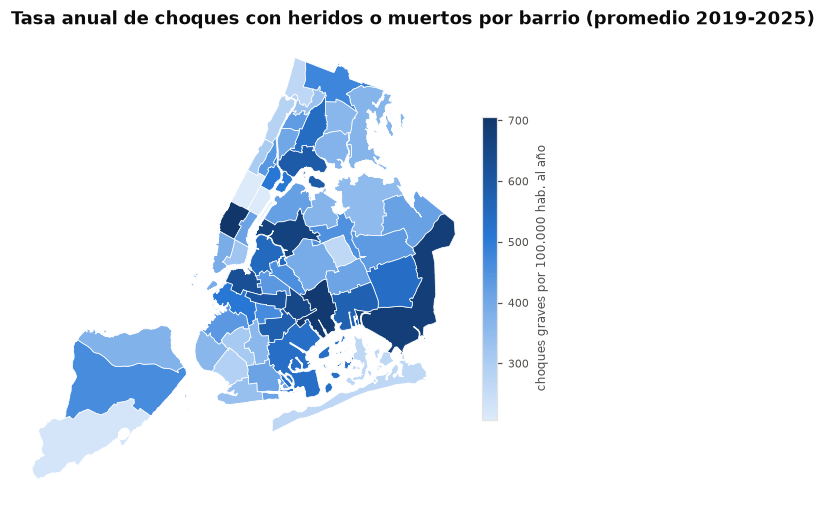

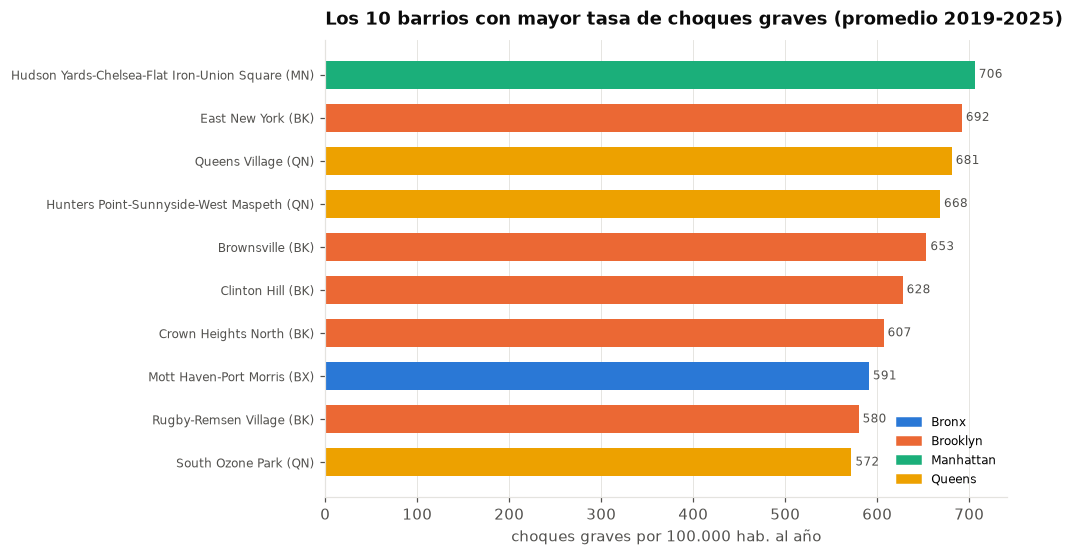

,etiqueta,poblacion_2018,choques_graves,tasa_choques_graves,tasa_heridos,pct_choques_graves
1,Hudson Yards-Chelsea-Flat Iron-Union Square (MN),148744,1050.1,706.0,811.0,29.6
2,East New York (BK),159382,1102.9,692.0,995.5,34.9
3,Queens Village (QN),192800,1312.9,680.9,998.4,35.7
4,Hunters Point-Sunnyside-West Maspeth (QN),136810,914.1,668.2,867.7,35.0
5,Brownsville (BK),123329,805.9,653.4,924.6,35.2
6,Clinton Hill (BK),121961,765.4,627.6,783.6,31.7
7,Crown Heights North (BK),126877,770.0,606.9,795.8,37.6
8,Mott Haven-Port Morris (BX),161641,955.1,590.9,807.7,33.8
9,Rugby-Remsen Village (BK),139873,810.9,579.7,829.2,39.5
10,South Ozone Park (QN),126092,721.1,571.9,822.4,36.4


In [10]:
mapa_barrios("tasa_choques_graves", "Tasa anual de choques con heridos o muertos por barrio (promedio 2019-2025)",
             "08_06_mapa_tasa_graves", "choques graves por 100.000 hab. al año")
top_graves = barrios.nlargest(10, "tasa_choques_graves")
barras_barrios(top_graves, "tasa_choques_graves", "Los 10 barrios con mayor tasa de choques graves (promedio 2019-2025)",
               "08_07_top_barrios_graves", "choques graves por 100.000 hab. al año")

tabla_4 = top_graves[["etiqueta", "poblacion_2018", "choques_graves", "tasa_choques_graves", "tasa_heridos", "pct_choques_graves"]].round(1).reset_index(drop=True)
tabla_4.index += 1
tabla_4.to_csv("../figuras/tabla_08_p4_top_barrios_graves.csv")
tabla_4

In [11]:
print(f"Respuesta: el barrio con mayor tasa es {top_graves.iloc[0]['etiqueta']}, con {miles(top_graves.iloc[0]['tasa_choques_graves'])} choques graves "
      f"por 100.000 habitantes al año; la mediana de los 55 barrios es {miles(barrios['tasa_choques_graves'].median())}.")
print(f"Los 10 barrios se reparten así por distrito: {top_graves['borough'].value_counts().to_dict()}.")
print(f"Juntos tienen el {100 * top_graves['poblacion_2018'].sum() / barrios['poblacion_2018'].sum():.1f} % de la población "
      f"y el {100 * top_graves['choques_graves'].sum() / barrios['choques_graves'].sum():.1f} % de los choques graves ubicados en un barrio.")

Respuesta: el barrio con mayor tasa es Hudson Yards-Chelsea-Flat Iron-Union Square (MN), con 706 choques graves por 100.000 habitantes al año; la mediana de los 55 barrios es 417.
Los 10 barrios se reparten así por distrito: {'Brooklyn': 5, 'Queens': 3, 'Manhattan': 1, 'Bronx': 1}.
Juntos tienen el 17.1 % de la población y el 25.5 % de los choques graves ubicados en un barrio.


## Pregunta 5. ¿Qué causas del choque y qué tipos de vehículo se asocian con una mayor proporción de choques con heridos o muertos?

Aquí la medida es el **porcentaje de choques graves** dentro de cada causa o tipo de vehículo. La línea punteada es el promedio de todos los choques, que sirve de referencia.

Ojo con la lectura: la base de datos solo incluye choques reportados a la policía, y los choques leves se reportan menos. Eso sube el porcentaje de graves en general, pero no impide comparar unas causas con otras.

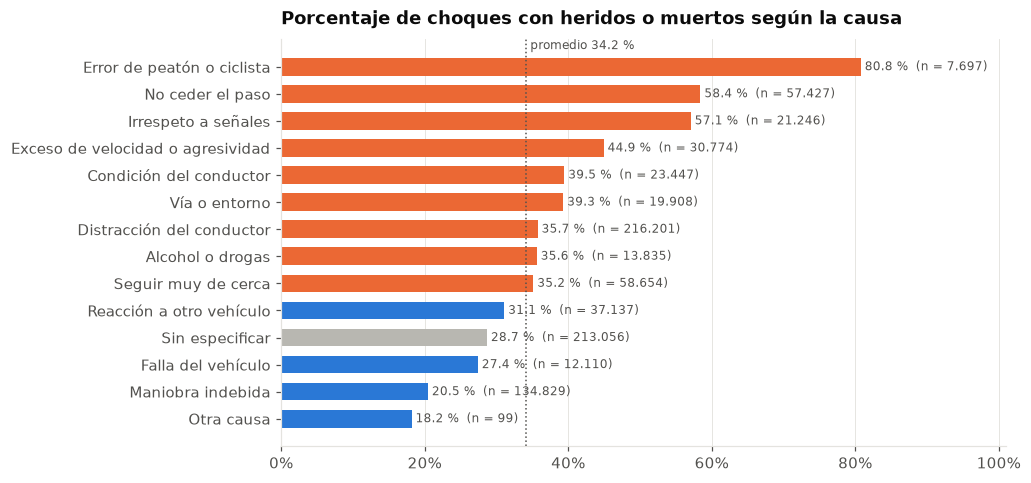

,causa,choques,graves,heridos,muertos,graves_pct,muertos_por_10_mil
0,Error de peatón o ciclista,7697,6218,6525,65,80.8,84.4
1,No ceder el paso,57427,33554,41244,160,58.4,27.9
2,Irrespeto a señales,21246,12129,17775,153,57.1,72.0
3,Exceso de velocidad o agresividad,30774,13832,21621,373,44.9,121.2
4,Condición del conductor,23447,9253,12808,137,39.5,58.4
5,Vía o entorno,19908,7827,10298,33,39.3,16.6
6,Distracción del conductor,216201,77282,101333,258,35.7,11.9
7,Alcohol o drogas,13835,4929,7534,65,35.6,47.0
8,Seguir muy de cerca,58654,20617,30586,5,35.2,0.9
9,Reacción a otro vehículo,37137,11548,17021,20,31.1,5.4


In [12]:
promedio_graves = choques.agg(F.avg("grave")).first()[0] * 100
causas = (choques.groupBy("causa").agg(F.count("*").alias("choques"), F.sum("grave").alias("graves"),
                                        F.sum("heridos").alias("heridos"), F.sum("muertos").alias("muertos"))
          .toPandas())
causas["graves_pct"] = 100 * causas["graves"] / causas["choques"]
causas["muertos_por_10_mil"] = 1e4 * causas["muertos"] / causas["choques"]
causas = causas.sort_values("graves_pct")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
colores = ["#b8b7b1" if c == SIN_CAUSA else (CATEGORICA[1] if v > promedio_graves else CATEGORICA[0]) for c, v in zip(causas["causa"], causas["graves_pct"])]
ax.barh(causas["causa"], causas["graves_pct"], color=colores, height=0.65)
for y, v, n in zip(causas["causa"], causas["graves_pct"], causas["choques"]):
    ax.text(v, y, f" {v:.1f} %  (n = {miles(n)})", va="center", fontsize=8, color=TINTA_SECUNDARIA)
ax.axvline(promedio_graves, color=TINTA_SECUNDARIA, linestyle=":", linewidth=1)
ax.text(promedio_graves, len(causas) - 0.35, f" promedio {promedio_graves:.1f} %", fontsize=8, color=TINTA_SECUNDARIA)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False); ax.margins(x=0.25)
ax.set_title("Porcentaje de choques con heridos o muertos según la causa", pad=10)
guardar(fig, "08_08_graves_por_causa"); plt.show()

tabla_5a = causas.sort_values("graves_pct", ascending=False).round(1).reset_index(drop=True)
tabla_5a.to_csv("../figuras/tabla_08_p5_causas.csv", index=False)
tabla_5a

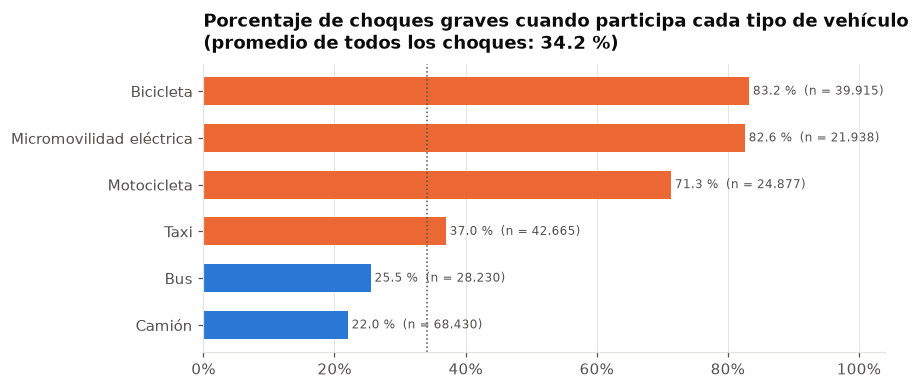

,vehículo involucrado,choques,graves_pct,muertos_por_10_mil,veces_el_promedio
0,Bicicleta,39915,83.25,34.07,2.44
1,Micromovilidad eléctrica,21938,82.60,83.42,2.42
2,Motocicleta,24877,71.34,140.69,2.09
3,Taxi,42665,36.97,13.13,1.08
4,Bus,28230,25.51,27.28,0.75
5,Camión,68430,22.02,40.77,0.64


In [13]:
NOMBRE_BANDERA = {"hay_moto": "Motocicleta", "hay_bici": "Bicicleta", "hay_micromovilidad": "Micromovilidad eléctrica",
                  "hay_camion": "Camión", "hay_bus": "Bus", "hay_taxi": "Taxi"}
fila = choques.agg(*[F.sum(b).alias(f"n_{b}") for b in BANDERAS_VEHICULO],
                   *[F.sum(F.col(b) * F.col("grave")).alias(f"g_{b}") for b in BANDERAS_VEHICULO],
                   *[F.sum(F.col(b) * F.col("muertos")).alias(f"m_{b}") for b in BANDERAS_VEHICULO]).first()
vehiculos_5 = pd.DataFrame([{"vehículo involucrado": NOMBRE_BANDERA[b], "choques": fila[f"n_{b}"],
                             "graves_pct": 100 * fila[f"g_{b}"] / fila[f"n_{b}"],
                             "muertos_por_10_mil": 1e4 * fila[f"m_{b}"] / fila[f"n_{b}"]} for b in BANDERAS_VEHICULO])
vehiculos_5["veces_el_promedio"] = vehiculos_5["graves_pct"] / promedio_graves
vehiculos_5 = vehiculos_5.sort_values("graves_pct")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(vehiculos_5["vehículo involucrado"], vehiculos_5["graves_pct"],
        color=[CATEGORICA[1] if v > promedio_graves else CATEGORICA[0] for v in vehiculos_5["graves_pct"]], height=0.6)
for y, v, n in zip(vehiculos_5["vehículo involucrado"], vehiculos_5["graves_pct"], vehiculos_5["choques"]):
    ax.text(v, y, f" {v:.1f} %  (n = {miles(n)})", va="center", fontsize=8, color=TINTA_SECUNDARIA)
ax.axvline(promedio_graves, color=TINTA_SECUNDARIA, linestyle=":", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False); ax.margins(x=0.25)
ax.set_title(f"Porcentaje de choques graves cuando participa cada tipo de vehículo\n(promedio de todos los choques: {promedio_graves:.1f} %)", pad=10)
guardar(fig, "08_09_graves_por_vehiculo"); plt.show()

tabla_5b = vehiculos_5.sort_values("graves_pct", ascending=False).round(2).reset_index(drop=True)
tabla_5b.to_csv("../figuras/tabla_08_p5_vehiculos.csv", index=False)
tabla_5b

In [14]:
con_causa = tabla_5a[tabla_5a["causa"] != SIN_CAUSA]
print(f"Respuesta: en promedio el {promedio_graves:.1f} % de los choques deja heridos o muertos.")
print("Causas con mayor proporción de graves:", "; ".join(f"{c} ({v:.1f} %)" for c, v in zip(con_causa["causa"].head(3), con_causa["graves_pct"].head(3))))
print("Causas con menor proporción:", "; ".join(f"{c} ({v:.1f} %)" for c, v in zip(con_causa["causa"].tail(3), con_causa["graves_pct"].tail(3))))
print("Vehículos:", "; ".join(f"{t} {v:.1f} % ({x:.1f} veces el promedio)" for t, v, x in
                              zip(tabla_5b["vehículo involucrado"], tabla_5b["graves_pct"], tabla_5b["veces_el_promedio"])))

Respuesta: en promedio el 34.2 % de los choques deja heridos o muertos.
Causas con mayor proporción de graves: Error de peatón o ciclista (80.8 %); No ceder el paso (58.4 %); Irrespeto a señales (57.1 %)
Causas con menor proporción: Falla del vehículo (27.4 %); Maniobra indebida (20.5 %); Otra causa (18.2 %)
Vehículos: Bicicleta 83.2 % (2.4 veces el promedio); Micromovilidad eléctrica 82.6 % (2.4 veces el promedio); Motocicleta 71.3 % (2.1 veces el promedio); Taxi 37.0 % (1.1 veces el promedio); Bus 25.5 % (0.8 veces el promedio); Camión 22.0 % (0.6 veces el promedio)


## Pregunta 6. ¿En qué horas y días se concentran los choques graves, y este patrón es homogéneo entre distritos?

Primero el patrón de toda la ciudad y después el de cada distrito. Para comparar distritos de distinto tamaño se usa el **porcentaje de los choques graves de cada distrito que ocurre en cada hora**.

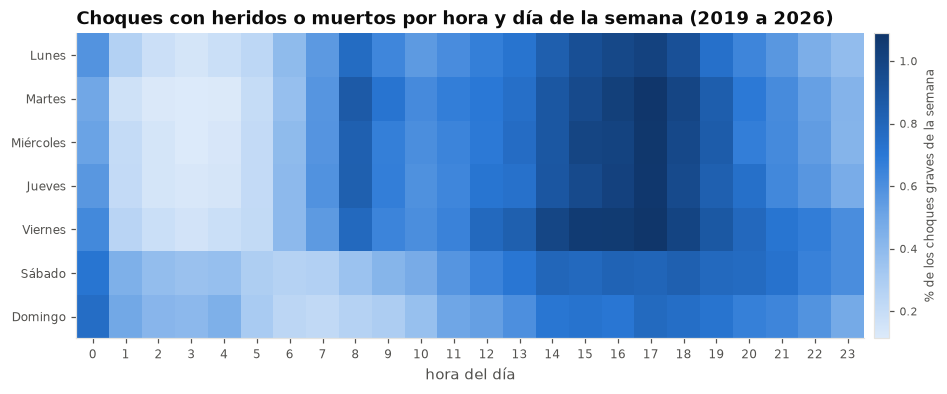

Las 5 franjas de una hora con más choques graves: Viernes 17:00 (1.09 %); Martes 17:00 (1.08 %); Miércoles 17:00 (1.08 %); Jueves 17:00 (1.08 %); Viernes 16:00 (1.06 %)
Entre las 14:00 y las 19:59 ocurre el 38.0 % de los choques graves; entre las 0:00 y las 5:59, el 12.6 %.


In [15]:
hd = (choques.filter((F.col("grave") == 1) & F.col("hora").isNotNull())
      .groupBy("borough", "dia_semana", "hora").count().toPandas())
ciudad = hd.groupby(["dia_semana", "hora"])["count"].sum().unstack("hora").reindex(index=ORDEN_DIAS, columns=range(24)).fillna(0)
ciudad_pct = 100 * ciudad / ciudad.values.sum()

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(ciudad_pct.values, aspect="auto", cmap=AZULES)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels(ciudad_pct.index, fontsize=8)
ax.set_xlabel("hora del día"); ax.grid(False)
barra = fig.colorbar(im, ax=ax, pad=0.01); barra.set_label("% de los choques graves de la semana", fontsize=8); barra.ax.tick_params(labelsize=7)
ax.set_title("Choques con heridos o muertos por hora y día de la semana (2019 a 2026)")
guardar(fig, "08_10_graves_hora_dia"); plt.show()

celdas = ciudad_pct.stack().sort_values(ascending=False)
print("Las 5 franjas de una hora con más choques graves:", "; ".join(f"{d} {h}:00 ({v:.2f} %)" for (d, h), v in celdas.head(5).items()))
por_hora = ciudad.sum()
print(f"Entre las 14:00 y las 19:59 ocurre el {100 * por_hora.loc[14:19].sum() / por_hora.sum():.1f} % de los choques graves; "
      f"entre las 0:00 y las 5:59, el {100 * por_hora.loc[0:5].sum() / por_hora.sum():.1f} %.")

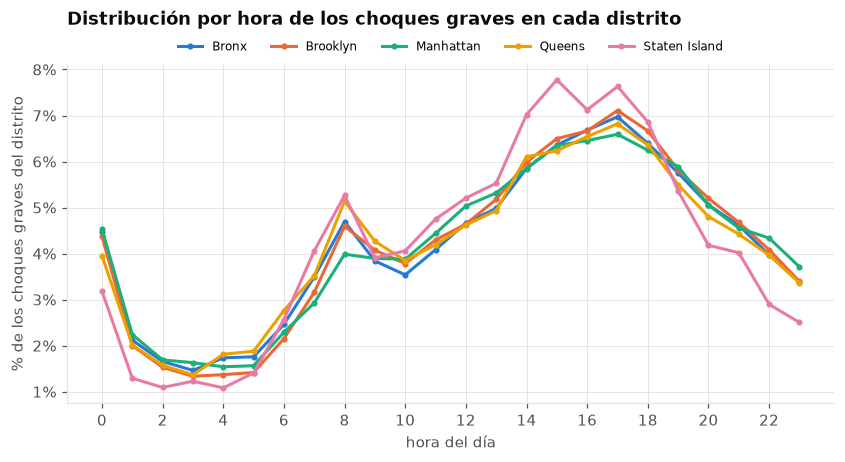

,graves_de_noche_pct,graves_en_fin_de_semana_pct,pct_graves_de_noche,pct_graves_de_dia,hora_pico
borough,,,,,
Bronx,30.2,26.5,36.6,33.7,17
Brooklyn,29.4,26.1,38.4,34.5,17
Manhattan,30.9,26.6,34.5,30.6,17
Queens,29.2,26.9,34.4,33.6,17
Staten Island,22.9,24.5,31.1,34.9,15


borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
borough,,,,,
Bronx,1.00,0.98,0.96,0.97,0.92
Brooklyn,0.98,1.00,0.97,0.98,0.92
Manhattan,0.96,0.97,1.00,0.94,0.89
Queens,0.97,0.98,0.94,1.00,0.94
Staten Island,0.92,0.92,0.89,0.94,1.00


In [16]:
perfil = hd[hd["borough"].notna()].groupby(["borough", "hora"])["count"].sum().unstack("borough").reindex(index=range(24), columns=BOROUGHS).fillna(0)
perfil_pct = 100 * perfil / perfil.sum()

fig, ax = plt.subplots(figsize=(9, 4))
for b in BOROUGHS:
    ax.plot(perfil_pct.index, perfil_pct[b], color=COLOR_BOROUGH[b], label=b, marker="o", markersize=3)
ax.set_xticks(range(0, 24, 2)); ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("hora del día"); ax.set_ylabel("% de los choques graves del distrito")
ax.legend(ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Distribución por hora de los choques graves en cada distrito", pad=26)
guardar(fig, "08_11_graves_hora_distrito"); plt.show()

# Patrón de 168 celdas (7 días x 24 horas) de cada distrito, para ver qué tan parecidos son
celdas_b = hd[hd["borough"].notna()].pivot_table(index=["dia_semana", "hora"], columns="borough", values="count", aggfunc="sum", fill_value=0)[BOROUGHS]
parecido = (100 * celdas_b / celdas_b.sum()).corr().round(2)

# El porcentaje de graves se calcula en Spark porque necesita todos los choques, no solo los graves
franjas = (choques.filter(F.col("borough").isNotNull() & F.col("hora").isNotNull())
           .withColumn("noche", ((F.col("hora") >= 20) | (F.col("hora") < 6)).cast("int"))
           .groupBy("borough").agg(
               F.round(100 * F.sum(F.col("noche") * F.col("grave")) / F.sum("grave"), 1).alias("graves_de_noche_pct"),
               F.round(100 * F.sum(F.col("fin_de_semana") * F.col("grave")) / F.sum("grave"), 1).alias("graves_en_fin_de_semana_pct"),
               F.round(100 * F.sum(F.col("noche") * F.col("grave")) / F.sum("noche"), 1).alias("pct_graves_de_noche"),
               F.round(100 * F.sum((1 - F.col("noche")) * F.col("grave")) / F.sum(1 - F.col("noche")), 1).alias("pct_graves_de_dia"))
           .toPandas().set_index("borough").reindex(BOROUGHS))
franjas["hora_pico"] = perfil_pct.idxmax()
franjas.to_csv("../figuras/tabla_08_p6_franjas_distrito.csv")
parecido.to_csv("../figuras/tabla_08_p6_parecido_distritos.csv")
display(franjas); parecido

In [17]:
menor = parecido.where(~np.eye(5, dtype=bool)).stack().idxmin()
print(f"Respuesta: la hora con más choques graves es las {int(por_hora.idxmax())}:00 en la ciudad; por distrito: "
      + ", ".join(f"{b} {int(h)}:00" for b, h in franjas["hora_pico"].items()) + ".")
print(f"El patrón semanal de los distritos es muy parecido: la correlación entre sus 168 celdas va de "
      f"{parecido.where(~np.eye(5, dtype=bool)).min().min():.2f} a {parecido.where(~np.eye(5, dtype=bool)).max().max():.2f} "
      f"(la pareja menos parecida es {menor[0]} y {menor[1]}).")
print("Donde sí hay diferencias es en el peso de la noche (de 20:00 a 5:59):",
      ", ".join(f"{b} {v:.1f} %" for b, v in franjas["graves_de_noche_pct"].items()) + ".")
print("Porcentaje de choques que dejan víctimas, de noche frente a de día:",
      ", ".join(f"{b} {n:.1f} % de noche frente a {d:.1f} % de día" for b, n, d in
                zip(franjas.index, franjas["pct_graves_de_noche"], franjas["pct_graves_de_dia"])) + ".")

Respuesta: la hora con más choques graves es las 17:00 en la ciudad; por distrito: Bronx 17:00, Brooklyn 17:00, Manhattan 17:00, Queens 17:00, Staten Island 15:00.
El patrón semanal de los distritos es muy parecido: la correlación entre sus 168 celdas va de 0.89 a 0.98 (la pareja menos parecida es Manhattan y Staten Island).
Donde sí hay diferencias es en el peso de la noche (de 20:00 a 5:59): Bronx 30.2 %, Brooklyn 29.4 %, Manhattan 30.9 %, Queens 29.2 %, Staten Island 22.9 %.
Porcentaje de choques que dejan víctimas, de noche frente a de día: Bronx 36.6 % de noche frente a 33.7 % de día, Brooklyn 38.4 % de noche frente a 34.5 % de día, Manhattan 34.5 % de noche frente a 30.6 % de día, Queens 34.4 % de noche frente a 33.6 % de día, Staten Island 31.1 % de noche frente a 34.9 % de día.


## Pregunta 7. ¿Qué barrios combinan una alta tasa de arrestos con una alta tasa de choques graves y deberían priorizarse?

Un barrio se considera **alto** en un indicador si está en la cuarta parte más alta de los 55 barrios (percentil 75 o más). Los barrios altos en los dos indicadores a la vez son los prioritarios. El umbral es una decisión nuestra: con el percentil 75 quedan pocos barrios, que es lo que sirve para priorizar.

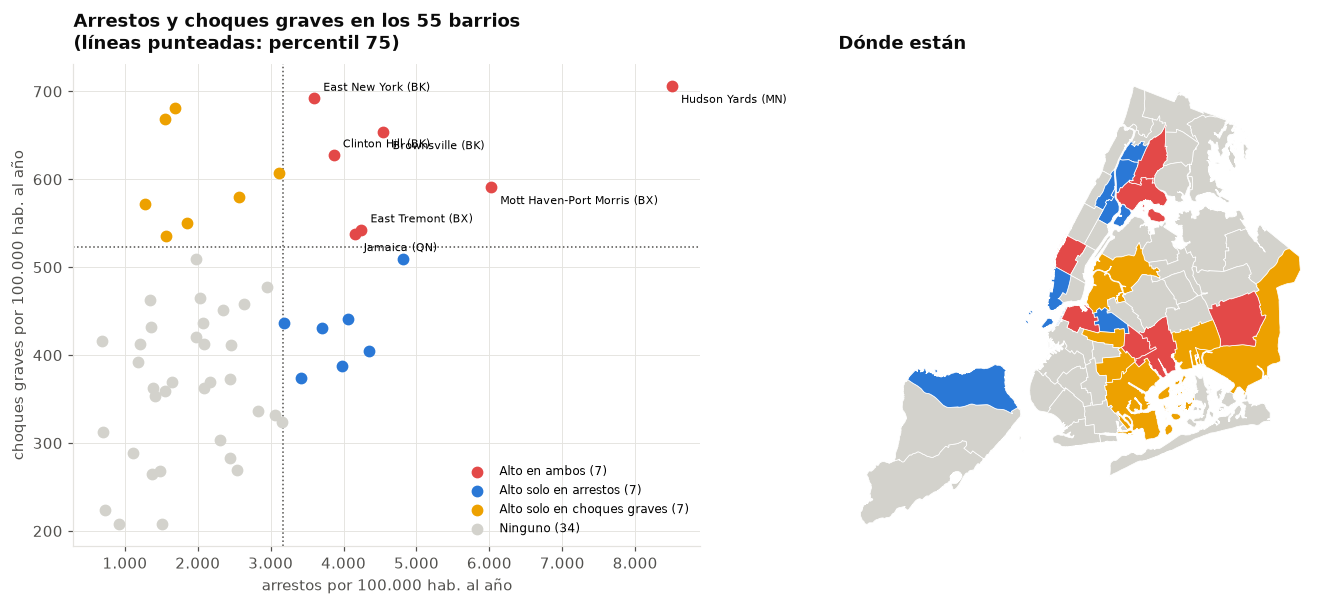

,etiqueta,poblacion_2018,tasa_arrestos,posicion_arrestos,tasa_choques_graves,posicion_graves
0,Hudson Yards-Chelsea-Flat Iron-Union Square (MN),148744,8504.0,1,706.0,1
1,East New York (BK),159382,3596.0,12,692.0,2
2,Brownsville (BK),123329,4545.0,4,653.0,5
3,Clinton Hill (BK),121961,3865.0,10,628.0,6
4,Mott Haven-Port Morris (BX),161641,6024.0,2,591.0,8
5,East Tremont (BX),165682,4243.0,6,542.0,12
6,Jamaica (QN),226348,4151.0,7,537.0,13


In [18]:
umbral_arrestos = barrios["tasa_arrestos"].quantile(0.75)
umbral_graves = barrios["tasa_choques_graves"].quantile(0.75)
alto_a, alto_g = barrios["tasa_arrestos"] >= umbral_arrestos, barrios["tasa_choques_graves"] >= umbral_graves
barrios["prioridad"] = np.select([alto_a & alto_g, alto_a, alto_g], ["Alto en ambos", "Alto solo en arrestos", "Alto solo en choques graves"], "Ninguno")
COLOR_PRIORIDAD = {"Alto en ambos": "#e34948", "Alto solo en arrestos": CATEGORICA[0], "Alto solo en choques graves": CATEGORICA[3], "Ninguno": "#d3d2cc"}

fig, (ax, ax_mapa) = plt.subplots(1, 2, figsize=(12.5, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
for categoria, color in COLOR_PRIORIDAD.items():
    grupo = barrios[barrios["prioridad"] == categoria]
    ax.scatter(grupo["tasa_arrestos"], grupo["tasa_choques_graves"], color=color, s=45, label=f"{categoria} ({len(grupo)})", zorder=3)
ax.axvline(umbral_arrestos, color=TINTA_SECUNDARIA, linestyle=":", linewidth=1); ax.axhline(umbral_graves, color=TINTA_SECUNDARIA, linestyle=":", linewidth=1)
# las etiquetas se alternan arriba y abajo del punto para que no se monten, y las muy largas se recortan
for i, (_, f) in enumerate(barrios[barrios["prioridad"] == "Alto en ambos"].sort_values("tasa_choques_graves").iterrows()):
    texto = f["etiqueta"] if len(f["etiqueta"]) <= 30 else f["barrio"].split("-")[0] + f" ({SIGLA[f['borough']]})"
    ax.annotate(texto, (f["tasa_arrestos"], f["tasa_choques_graves"]), textcoords="offset points",
                xytext=(6, 5 if i % 2 else -11), fontsize=7)
fmt_miles(ax, "x"); fmt_miles(ax, "y")
ax.set_xlabel("arrestos por 100.000 hab. al año"); ax.set_ylabel("choques graves por 100.000 hab. al año")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Arrestos y choques graves en los 55 barrios\n(líneas punteadas: percentil 75)", pad=10)
geo.dibujar_pumas(ax_mapa, pumas, {p: COLOR_PRIORIDAD[c] for p, c in zip(barrios["puma"], barrios["prioridad"])})
ax_mapa.set_title("Dónde están", pad=10)
fig.tight_layout()
guardar(fig, "08_12_barrios_prioritarios"); plt.show()

prioritarios = (barrios[barrios["prioridad"] == "Alto en ambos"]
                .assign(posicion_arrestos=barrios["tasa_arrestos"].rank(ascending=False).astype(int),
                        posicion_graves=barrios["tasa_choques_graves"].rank(ascending=False).astype(int))
                .sort_values("tasa_choques_graves", ascending=False))
tabla_7 = prioritarios[["etiqueta", "poblacion_2018", "tasa_arrestos", "posicion_arrestos", "tasa_choques_graves", "posicion_graves"]].round(0).reset_index(drop=True)
tabla_7.to_csv("../figuras/tabla_08_p7_barrios_prioritarios.csv", index=False)
barrios[["puma", "etiqueta", "borough", "prioridad", "tasa_arrestos", "tasa_choques_graves"]].round(1).to_csv("../figuras/tabla_08_p7_todos_los_barrios.csv", index=False)
tabla_7

In [19]:
pearson, spearman = correlaciones(barrios, "tasa_arrestos", "tasa_choques_graves")
print(f"Respuesta: {len(prioritarios)} de los 55 barrios están en la cuarta parte más alta en los dos indicadores "
      f"(umbrales: {miles(umbral_arrestos)} arrestos y {miles(umbral_graves)} choques graves por 100.000 habitantes al año).")
print(f"Por distrito: {prioritarios['borough'].value_counts().to_dict()}. Tienen el "
      f"{100 * prioritarios['poblacion_2018'].sum() / barrios['poblacion_2018'].sum():.1f} % de la población de la ciudad.")
print(f"En los 55 barrios, las dos tasas se mueven juntas con una correlación de Spearman de {spearman:+.2f} (Pearson {pearson:+.2f}).")

Respuesta: 7 de los 55 barrios están en la cuarta parte más alta en los dos indicadores (umbrales: 3.170 arrestos y 523 choques graves por 100.000 habitantes al año).
Por distrito: {'Brooklyn': 3, 'Bronx': 2, 'Manhattan': 1, 'Queens': 1}. Tienen el 13.2 % de la población de la ciudad.
En los 55 barrios, las dos tasas se mueven juntas con una correlación de Spearman de +0.43 (Pearson +0.49).


## Pregunta 8. ¿Los arrestos por infracciones de tránsito y conducción bajo estado de embriaguez se concentran en las zonas con mayor accidentalidad grave?

Se compara, barrio por barrio, la tasa de arrestos de tránsito con la tasa de choques graves. Si el control se concentrara donde está el problema, los barrios con más choques graves tendrían también más arrestos de tránsito. Además se buscan las **brechas**: barrios en la cuarta parte más alta de choques graves que están en la mitad baja de arrestos de tránsito.

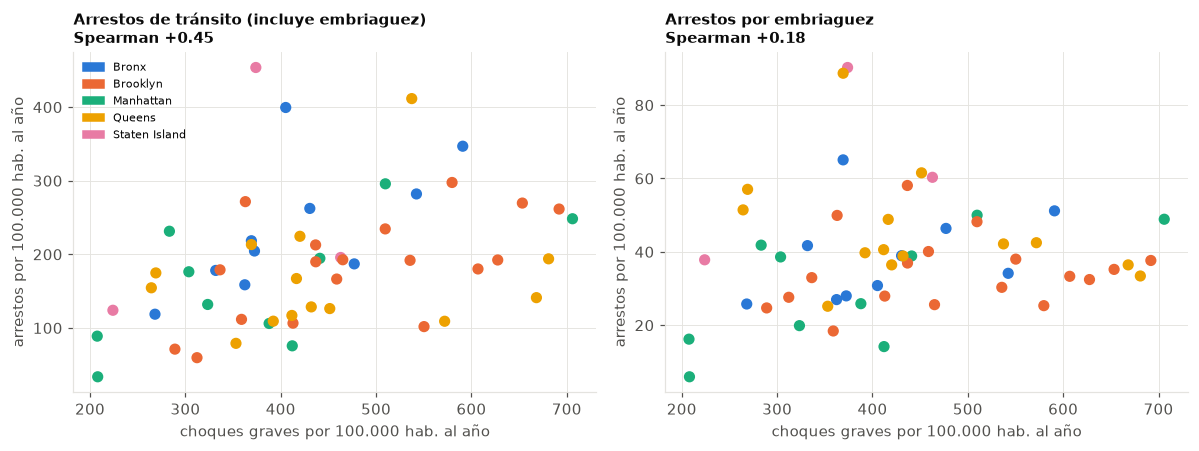

,pearson,spearman
serie,,
Arrestos de tránsito (incluye embriaguez),0.38,0.45
Arrestos por embriaguez,0.10,0.18


,etiqueta,tasa_choques_graves,posicion_graves,tasa_arrestos_transito,posicion_transito,tasa_arrestos_embriaguez
0,Hudson Yards-Chelsea-Flat Iron-Union Square (MN),706.0,1,248.4,12,48.9
1,East New York (BK),692.0,2,261.5,11,37.6
2,Queens Village (QN),680.9,3,193.9,22,33.4
3,Hunters Point-Sunnyside-West Maspeth (QN),668.2,4,141.2,37,36.4
4,Brownsville (BK),653.4,5,269.7,9,35.2
5,Clinton Hill (BK),627.6,6,192.3,24,32.4
6,Crown Heights North (BK),606.9,7,180.2,28,33.3
7,Mott Haven-Port Morris (BX),590.9,8,346.9,4,51.2
8,Rugby-Remsen Village (BK),579.7,9,297.6,5,25.3
9,South Ozone Park (QN),571.9,10,109.1,46,42.5


In [20]:
series_8 = [("tasa_arrestos_transito", "Arrestos de tránsito (incluye embriaguez)"), ("tasa_arrestos_embriaguez", "Arrestos por embriaguez")]
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
filas = []
for ax, (columna, titulo) in zip(ejes, series_8):
    pearson, spearman = correlaciones(barrios, "tasa_choques_graves", columna)
    filas.append({"serie": titulo, "pearson": round(pearson, 2), "spearman": round(spearman, 2)})
    ax.scatter(barrios["tasa_choques_graves"], barrios[columna], color=[COLOR_BOROUGH[b] for b in barrios["borough"]], s=40, zorder=3)
    fmt_miles(ax, "x"); fmt_miles(ax, "y")
    ax.set_xlabel("choques graves por 100.000 hab. al año"); ax.set_ylabel("arrestos por 100.000 hab. al año")
    ax.set_title(f"{titulo}\nSpearman {spearman:+.2f}", fontsize=10)
ejes[0].legend(handles=[Patch(color=COLOR_BOROUGH[b], label=b) for b in BOROUGHS], fontsize=7, loc="upper left")
fig.tight_layout()
guardar(fig, "08_13_arrestos_transito_vs_graves"); plt.show()

correlacion_8 = pd.DataFrame(filas).set_index("serie")
brecha = barrios[(barrios["tasa_choques_graves"] >= umbral_graves) & (barrios["tasa_arrestos_transito"] <= barrios["tasa_arrestos_transito"].median())]
tabla_8 = (barrios.assign(posicion_graves=barrios["tasa_choques_graves"].rank(ascending=False).astype(int),
                          posicion_transito=barrios["tasa_arrestos_transito"].rank(ascending=False).astype(int))
           .nlargest(10, "tasa_choques_graves")
           [["etiqueta", "tasa_choques_graves", "posicion_graves", "tasa_arrestos_transito", "posicion_transito", "tasa_arrestos_embriaguez"]]
           .round(1).reset_index(drop=True))
tabla_8.to_csv("../figuras/tabla_08_p8_transito_vs_graves.csv", index=False)
correlacion_8.to_csv("../figuras/tabla_08_p8_correlaciones.csv")
display(correlacion_8); tabla_8

In [21]:
total_transito = barrios["arrestos_transito"].sum()
print(f"Respuesta: en los 55 barrios, la correlación de Spearman entre choques graves y arrestos de tránsito es "
      f"{correlacion_8['spearman'].iloc[0]:+.2f}, y con los arrestos por embriaguez es {correlacion_8['spearman'].iloc[1]:+.2f}.")
print(f"Los 10 barrios con más choques graves por habitante reciben el "
      f"{100 * barrios.nlargest(10, 'tasa_choques_graves')['arrestos_transito'].sum() / total_transito:.1f} % de los arrestos de tránsito "
      f"y tienen el {100 * barrios.nlargest(10, 'tasa_choques_graves')['poblacion_2018'].sum() / barrios['poblacion_2018'].sum():.1f} % de la población.")
print(f"Brechas (muchos choques graves y pocos arrestos de tránsito): {len(brecha)} barrios"
      + (": " + "; ".join(brecha.sort_values("tasa_choques_graves", ascending=False)["etiqueta"]) if len(brecha) else "") + ".")

Respuesta: en los 55 barrios, la correlación de Spearman entre choques graves y arrestos de tránsito es +0.45, y con los arrestos por embriaguez es +0.18.
Los 10 barrios con más choques graves por habitante reciben el 20.8 % de los arrestos de tránsito y tienen el 17.1 % de la población.
Brechas (muchos choques graves y pocos arrestos de tránsito): 4 barrios: Hunters Point-Sunnyside-West Maspeth (QN); Crown Heights North (BK); South Ozone Park (QN); North Side-South Side (BK).


## Conclusiones

Las frases de respuesta de cada pregunta quedan arriba, con las cifras de esta ejecución. Lo que hay que tener presente al usarlas:

- Todas las tasas son por residente y promedian 2019 a 2025; la población por barrio es la de 2010 ajustada a 2018.
- La relación entre pobreza y arrestos se observa con solo cinco distritos: sirve para describir, no para afirmar que una cosa causa la otra.
- Los arrestos reflejan dónde actúa la policía. Que un barrio tenga pocos arrestos de tránsito y muchos choques graves señala una posible brecha de control, no que allí se cometan menos infracciones.
- Las figuras y tablas de este notebook quedan en `figuras/` con el prefijo `08_`.